In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("All libraries imported successfully!")

All libraries imported successfully!



# SARIMAX Demand Forecasting

## 1. Introduction

This notebook focuses on forecasting daily product demand using the SARIMAX (Seasonal AutoRegressive Integrated Moving Average with eXogenous factors) model.

The objective is to predict future demand, identify weekly seasonal patterns, and compare SARIMAX performance against a Naive Forecasting baseline.

The model is evaluated using:
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Weighted Absolute Percentage Error (WAPE)

A chronological train-test split is used to ensure that future observations are not used during model training.


In [21]:
# Generate dummy daily demand data

np.random.seed(42)

dates = pd.date_range(
    start="2023-01-01",
    periods=730,
    freq="D"
)

trend = np.linspace(100, 160, 730)

weekly_seasonality = 20 * np.sin(
    2 * np.pi * np.arange(730) / 7
)

yearly_seasonality = 12 * np.sin(
    2 * np.pi * np.arange(730) / 365
)

random_noise = np.random.normal(0, 8, 730)

demand = (
    trend
    + weekly_seasonality
    + yearly_seasonality
    + random_noise
)

demand = np.maximum(demand, 0).round().astype(int)

df = pd.DataFrame({
    "date": dates,
    "demand": demand
})

print("Dummy dataset generated successfully!")
print("Dataset shape:", df.shape)

display(df.head(10))

Dummy dataset generated successfully!
Dataset shape: (730, 2)


,date,demand
0,2023-01-01,104
1,2023-01-02,115
2,2023-01-03,125
3,2023-01-04,122
4,2023-01-05,91
5,2023-01-06,80
6,2023-01-07,99
7,2023-01-08,108
8,2023-01-09,114
9,2023-01-10,126


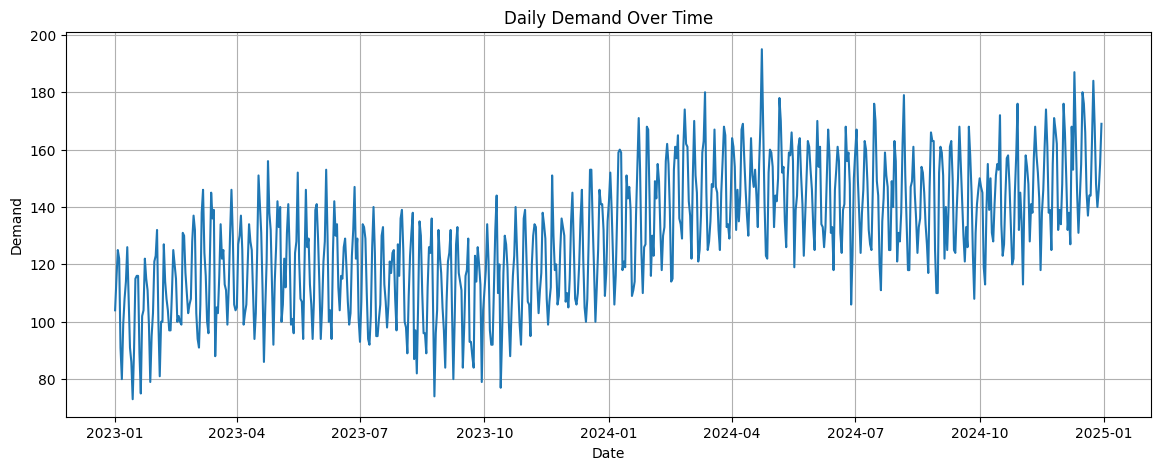

In [22]:
plt.figure(figsize=(14, 5))

plt.plot(df["date"], df["demand"])

plt.title("Daily Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.grid(True)

plt.show()

In [23]:
# Convert date column into time-series index

df["date"] = pd.to_datetime(df["date"])

daily_data = df.set_index("date")["demand"]

# Chronological 80-20 split

split_index = int(len(daily_data) * 0.80)

train_data = daily_data.iloc[:split_index]
test_data = daily_data.iloc[split_index:]

print("Training observations:", len(train_data))
print("Testing observations:", len(test_data))

print("\nTraining period:")
print(train_data.index.min(), "to", train_data.index.max())

print("\nTesting period:")
print(test_data.index.min(), "to", test_data.index.max())

Training observations: 584
Testing observations: 146

Training period:
2023-01-01 00:00:00 to 2024-08-06 00:00:00

Testing period:
2024-08-07 00:00:00 to 2024-12-30 00:00:00


In [24]:
# Naive Forecasting Baseline

last_value = train_data.iloc[-1]

naive_predictions = np.repeat(
    last_value,
    len(test_data)
)

naive_forecast = pd.Series(
    naive_predictions,
    index=test_data.index
)

print("Naive baseline created successfully!")
print("Last training demand:", last_value)
print("Forecast observations:", len(naive_forecast))

Naive baseline created successfully!
Last training demand: 179
Forecast observations: 146


In [25]:
# Evaluation metrics

def calculate_metrics(actual, predicted):

    mae = np.mean(np.abs(actual - predicted))

    rmse = np.sqrt(
        np.mean((actual - predicted) ** 2)
    )

    wape = (
        np.sum(np.abs(actual - predicted))
        / np.sum(np.abs(actual))
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE": wape
    }


naive_metrics = calculate_metrics(
    test_data.values,
    naive_forecast.values
)

print("Naive Forecasting Evaluation:")
print("--------------------------------")

for metric, value in naive_metrics.items():
    print(f"{metric}: {value:.2f}")

Naive Forecasting Evaluation:
--------------------------------
MAE: 34.15
RMSE: 37.85
WAPE: 23.55


## 2. SARIMAX Model Explanation

SARIMAX is a time-series forecasting technique that combines autoregression, differencing, moving averages, and seasonal components.

The model is useful for demand forecasting because demand may contain:
- Trends over time
- Weekly seasonal patterns
- Random fluctuations

The seasonal period is set to 7 to investigate weekly demand patterns in daily observations.

The model parameters are:
- **p:** Autoregressive order
- **d:** Degree of differencing
- **q:** Moving average order
- **P:** Seasonal autoregressive order
- **D:** Seasonal differencing order
- **Q:** Seasonal moving average order
- **s:** Seasonal period

In [26]:
import warnings
import itertools

warnings.filterwarnings("ignore")

# Divide training data into fitting and validation sets
validation_size = 30

fitting_data = train_data.iloc[:-validation_size]
validation_data = train_data.iloc[-validation_size:]

# Candidate parameters
orders = [
    (0, 0, 0),
    (1, 0, 0),
    (0, 1, 1),
    (1, 1, 1)
]

seasonal_orders = [
    (0, 0, 0, 7),
    (1, 0, 0, 7),
    (0, 1, 1, 7)
]

best_rmse = float("inf")
best_order = None
best_seasonal_order = None

# Search for best parameters
for order, seasonal_order in itertools.product(
    orders, seasonal_orders
):
    try:
        model = SARIMAX(
            fitting_data,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        fitted_model = model.fit(disp=False, maxiter=100)

        predictions = fitted_model.forecast(
            steps=len(validation_data)
        )

        rmse = np.sqrt(
            np.mean(
                (validation_data.values - predictions.values) ** 2
            )
        )

        print(order, seasonal_order, "RMSE:", round(rmse, 2))

        if rmse < best_rmse:
            best_rmse = rmse
            best_order = order
            best_seasonal_order = seasonal_order

    except Exception:
        continue

print("\nBest SARIMAX order:", best_order)
print("Best seasonal order:", best_seasonal_order)
print("Best validation RMSE:", round(best_rmse, 2))

(0, 0, 0) (0, 0, 0, 7) RMSE: 145.17
(0, 0, 0) (1, 0, 0, 7) RMSE: 10.23
(0, 0, 0) (0, 1, 1, 7) RMSE: 9.44
(1, 0, 0) (0, 0, 0, 7) RMSE: 24.1
(1, 0, 0) (1, 0, 0, 7) RMSE: 10.22
(1, 0, 0) (0, 1, 1, 7) RMSE: 9.42
(0, 1, 1) (0, 0, 0, 7) RMSE: 17.52
(0, 1, 1) (1, 0, 0, 7) RMSE: 12.43
(0, 1, 1) (0, 1, 1, 7) RMSE: 9.68
(1, 1, 1) (0, 0, 0, 7) RMSE: 17.31
(1, 1, 1) (1, 0, 0, 7) RMSE: 12.66
(1, 1, 1) (0, 1, 1, 7) RMSE: 9.68

Best SARIMAX order: (1, 0, 0)
Best seasonal order: (0, 1, 1, 7)
Best validation RMSE: 9.42


In [27]:
# Train the best SARIMAX model using full training data

best_model = SARIMAX(
    train_data,
    order=best_order,
    seasonal_order=best_seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

best_fitted_model = best_model.fit(disp=False)

print("Best SARIMAX model trained successfully!")
print(best_fitted_model.summary())

Best SARIMAX model trained successfully!
                                      SARIMAX Results                                      
Dep. Variable:                              demand   No. Observations:                  584
Model:             SARIMAX(1, 0, 0)x(0, 1, [1], 7)   Log Likelihood               -2068.567
Date:                             Fri, 13 Nov 2026   AIC                           4143.133
Time:                                     14:19:19   BIC                           4156.165
Sample:                                 01-01-2023   HQIC                          4148.218
                                      - 08-06-2024                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1170      0.046      2.566      0.010       0.02

In [28]:
# Generate forecasts for test data

forecast_result = best_fitted_model.get_forecast(
    steps=len(test_data)
)

predictions = forecast_result.predicted_mean

# Prediction intervals
confidence_intervals = forecast_result.conf_int()

print("Forecasts:")
print(predictions)

print("\nPrediction Intervals:")
print(confidence_intervals)

Forecasts:
2024-08-07    154.820406
2024-08-08    135.139073
2024-08-09    125.895151
2024-08-10    125.165884
2024-08-11    142.339520
                 ...    
2024-12-26    134.988846
2024-12-27    125.877569
2024-12-28    125.163826
2024-12-29    142.339279
2024-12-30    155.614060
Freq: D, Name: predicted_mean, Length: 146, dtype: float64

Prediction Intervals:
            lower demand  upper demand
2024-08-07    136.862899    172.777914
2024-08-08    117.058998    153.219148
2024-08-09    107.813403    143.976900
2024-08-10    107.084113    143.247655
2024-08-11    124.257749    160.421292
...                  ...           ...
2024-12-26    103.004815    166.972876
2024-12-27     93.893438    157.861700
2024-12-28     93.179694    157.147959
2024-12-29    110.355147    174.323412
2024-12-30    123.629928    187.598193

[146 rows x 2 columns]


## 3. Model Evaluation

The forecasting models are evaluated using three metrics.

1. **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted demand.

2. **RMSE (Root Mean Squared Error):** Measures prediction error while giving greater importance to larger errors.

3. **WAPE (Weighted Absolute Percentage Error):** Measures total absolute forecast error as a percentage of total actual demand.

Lower values indicate better forecasting performance for all three metrics.

In [29]:
# Evaluation metrics

mae = mean_absolute_error(
    test_data, predictions
)

rmse = np.sqrt(
    mean_squared_error(test_data, predictions)
)

wape = (
    np.sum(np.abs(test_data.values - predictions.values))
    / np.sum(np.abs(test_data.values))
) * 100

print("SARIMAX Evaluation Results")
print("--------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("WAPE:", round(wape, 2), "%")

SARIMAX Evaluation Results
--------------------------
MAE: 8.6
RMSE: 10.42
WAPE: 5.93 %


In [30]:
# Create forecast output dataframe

forecast_df = pd.DataFrame({
    "date": test_data.index,
    "actual_demand": test_data.values,
    "predicted_demand": predictions.values,
    "lower_bound": confidence_intervals.iloc[:, 0].values,
    "upper_bound": confidence_intervals.iloc[:, 1].values
})

# Save predictions
forecast_df.to_csv(
    "sarimax_predictions.csv",
    index=False
)

print("Forecast predictions exported successfully!")
display(forecast_df.head())

Forecast predictions exported successfully!


,date,actual_demand,predicted_demand,lower_bound,upper_bound
0,2024-08-07,151,154.820406,136.862899,172.777914
1,2024-08-08,134,135.139073,117.058998,153.219148
2,2024-08-09,118,125.895151,107.813403,143.976900
3,2024-08-10,118,125.165884,107.084113,143.247655
4,2024-08-11,147,142.339520,124.257749,160.421292


In [31]:
metrics_df = pd.DataFrame({
    "Model": ["SARIMAX"],
    "MAE": [mae],
    "RMSE": [rmse],
    "WAPE": [wape]
})

metrics_df.to_csv(
    "sarimax_evaluation_metrics.csv",
    index=False
)

display(metrics_df)
print("Evaluation metrics saved successfully!")

,Model,MAE,RMSE,WAPE
0,SARIMAX,8.604132,10.423835,5.932203


Evaluation metrics saved successfully!


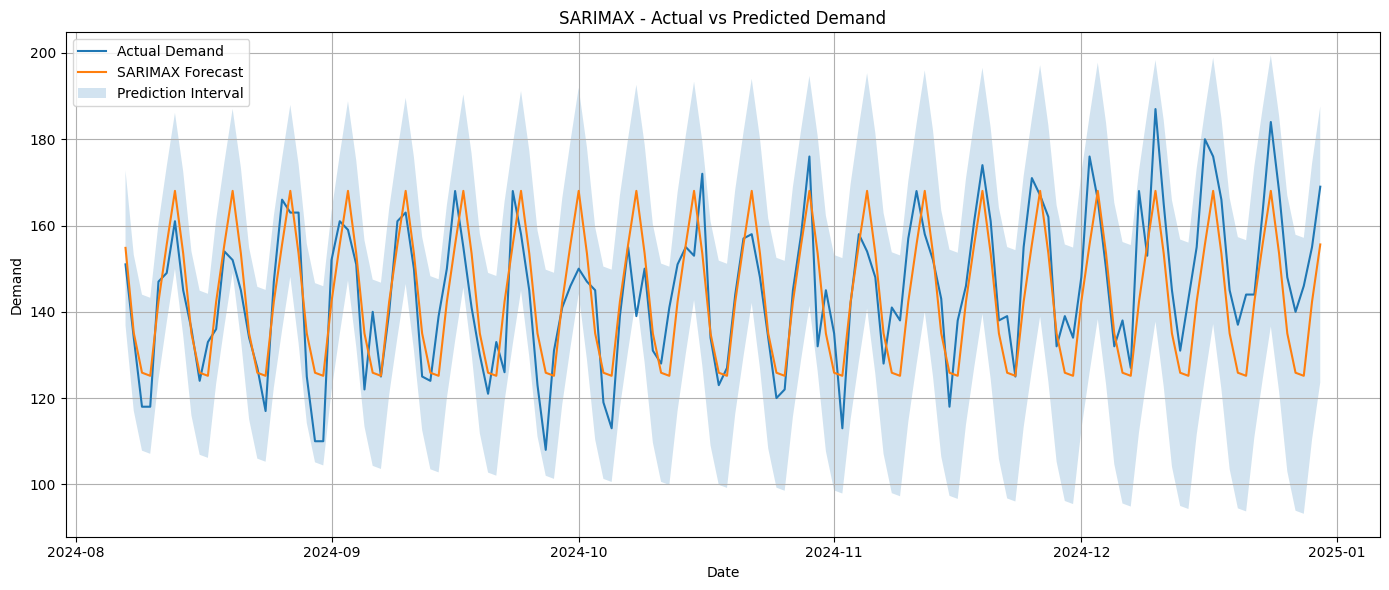

In [32]:
plt.figure(figsize=(14, 6))

plt.plot(
    test_data.index,
    test_data.values,
    label="Actual Demand"
)

plt.plot(
    test_data.index,
    predictions.values,
    label="SARIMAX Forecast"
)

plt.fill_between(
    test_data.index,
    confidence_intervals.iloc[:, 0],
    confidence_intervals.iloc[:, 1],
    alpha=0.2,
    label="Prediction Interval"
)

plt.title("SARIMAX - Actual vs Predicted Demand")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [33]:
# Train final SARIMAX model

final_model = SARIMAX(
    train_data,
    order=best_order,
    seasonal_order=best_seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

final_fitted_model = final_model.fit(
    disp=False,
    maxiter=200
)

print("Final SARIMAX model trained successfully!")
print(final_fitted_model.summary())

Final SARIMAX model trained successfully!
                                      SARIMAX Results                                      
Dep. Variable:                              demand   No. Observations:                  584
Model:             SARIMAX(1, 0, 0)x(0, 1, [1], 7)   Log Likelihood               -2068.567
Date:                             Fri, 13 Nov 2026   AIC                           4143.133
Time:                                     14:19:21   BIC                           4156.165
Sample:                                 01-01-2023   HQIC                          4148.218
                                      - 08-06-2024                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1170      0.046      2.566      0.010       0.0

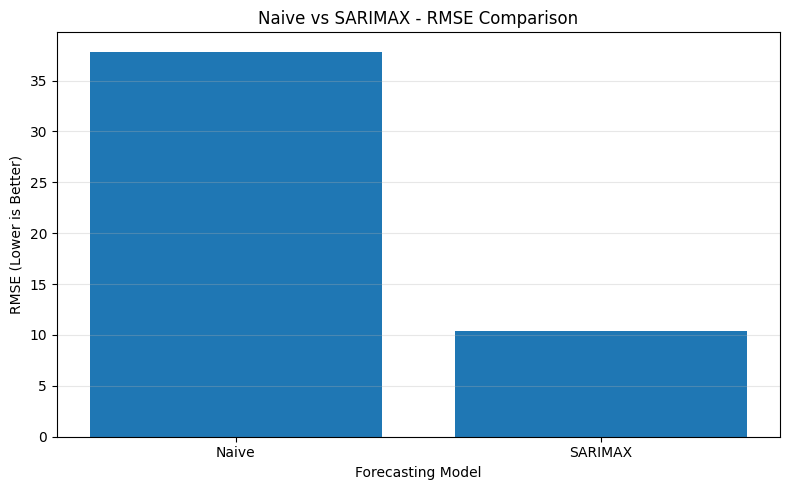

Naive RMSE: 37.851
SARIMAX RMSE: 10.424


In [34]:

# Compare Naive and SARIMAX forecasting performance

naive_rmse = np.sqrt(
    np.mean((test_data.values - naive_forecast.values) ** 2)
)

sarimax_rmse = np.sqrt(
    np.mean((test_data.values - predictions.values) ** 2)
)

models = ["Naive", "SARIMAX"]
rmse_values = [naive_rmse, sarimax_rmse]

plt.figure(figsize=(8, 5))
plt.bar(models, rmse_values)

plt.title("Naive vs SARIMAX - RMSE Comparison")
plt.xlabel("Forecasting Model")
plt.ylabel("RMSE (Lower is Better)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Naive RMSE:", round(naive_rmse, 3))
print("SARIMAX RMSE:", round(sarimax_rmse, 3))


## 4. Conclusion

This project implements a Naive Forecasting baseline and a SARIMAX model to forecast daily demand.

The models are compared using MAE, RMSE, and WAPE.

The SARIMAX model also generates 95% prediction intervals to represent forecast uncertainty.

The final model performance will be evaluated using the cleaned daily demand dataset.

This forecasting approach can support inventory planning by providing estimates of future product demand.

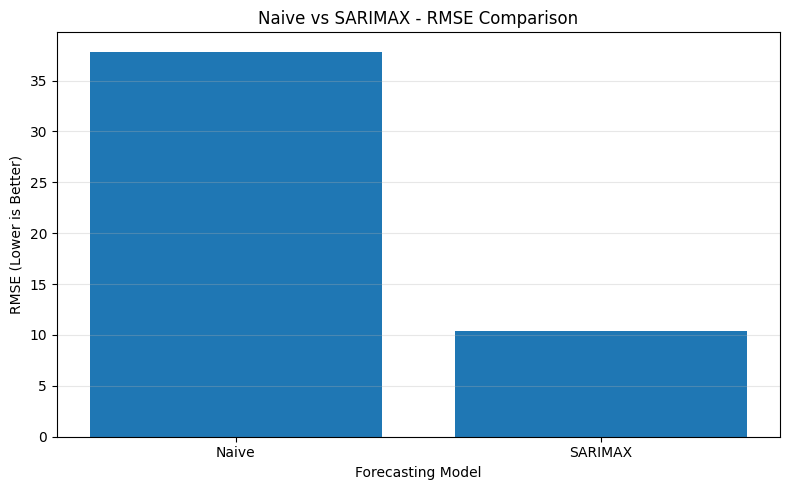

Naive RMSE: 37.851
SARIMAX RMSE: 10.424


In [35]:
# Compare Naive and SARIMAX forecasting performance

naive_rmse = np.sqrt(
    np.mean((test_data.values - naive_forecast.values) ** 2)
)

sarimax_rmse = np.sqrt(
    np.mean((test_data.values - predictions.values) ** 2)
)

models = ["Naive", "SARIMAX"]
rmse_values = [naive_rmse, sarimax_rmse]

plt.figure(figsize=(8, 5))
plt.bar(models, rmse_values)

plt.title("Naive vs SARIMAX - RMSE Comparison")
plt.xlabel("Forecasting Model")
plt.ylabel("RMSE (Lower is Better)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Naive RMSE:", round(naive_rmse, 3))
print("SARIMAX RMSE:", round(sarimax_rmse, 3))